# DL — BiGRU: OHLCV vs OHLCV + Indicators
### TCS Stock Price Prediction | Deep Learning — BiGRU (Bidirectional GRU)
**Target:** Predict next-day RETURN (back-converted to price for all metrics & graphs)
**Two Sets:** Set A (OHLCV, 5 features) · Set B (OHLCV + 9 Indicators, 14 features)
**Flow:** EDA -> Part A (OHLCV) -> Compute Indicators -> Part B -> Compare A vs B


## Why BiGRU for Stock Price Prediction?
> **BiGRU (Bidirectional GRU)s** use multi-head self-attention to capture dependencies across ALL positions in the sequence simultaneously — unlike RNNs which process sequentially.
> - Attention mechanisms allow the model to focus on the most relevant past days regardless of distance.
> - **Architecture:** Dense projection(32) -> Positional Encoding -> 2x Encoder Blocks (4-head MHA, FF=64, dropout 0.1, LayerNorm) -> GlobalAveragePooling1D -> Dense(16) -> Dense(1).
> - Vaswani et al. (2017) introduced BiGRUs; Wen & Liu (2023) applied them to financial time-series successfully.


In [1]:
# Dependencies ready
print('Environment ready!')


Environment ready!


---
## Step 0: Reproducibility — Set All Random Seeds to 42
Setting `numpy`, `python random`, and `tensorflow` seeds to **42** for fully reproducible results.


In [2]:
import os, random
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['PYTHONHASHSEED'] = '42'
random.seed(42)

import numpy as np
np.random.seed(42)

import tensorflow as tf
tf.random.set_seed(42)

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Dense, Dropout, Conv1D, MaxPooling1D, GlobalAveragePooling1D,
    Flatten, BatchNormalization, Input, MultiHeadAttention,
    LayerNormalization, Add, GRU, LSTM, Bidirectional,
    Softmax, Multiply, Lambda
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('All imports done! TensorFlow version:', tf.__version__)
print('All random seeds set to 42.')


All imports done! TensorFlow version: 2.21.0
All random seeds set to 42.


---
## Step 1: Load TCS Dataset
Reading `TCS.csv` (skiprows=[1,2]), parsing date index, keeping OHLCV columns, dropping NaN rows.


In [3]:
df = pd.read_csv('TCS.csv', skiprows=[1, 2])
if 'Price' in df.columns:
    df.rename(columns={'Price': 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df = df.sort_index()[['Open', 'High', 'Low', 'Close', 'Volume']]

for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)
print(f'Shape: {df.shape}')
print(f'Date range: {df.index.min().date()} to {df.index.max().date()}')
df.head()


Shape: (5363, 5)
Date range: 2005-01-03 to 2026-09-23


,Open,High,Low,Close,Volume
Date,,,,,
2005-01-03,106.283498,107.973897,106.283498,107.700127,4734168
2005-01-04,107.440734,107.759077,106.100513,106.745155,4979104
2005-01-05,106.660803,106.660803,101.893625,105.451103,9604320
2005-01-06,105.053169,107.122398,102.864561,105.089775,8006888
2005-01-07,105.848984,107.042770,104.468971,106.641655,7623136


In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print(f'Volume == 0: {(df["Volume"] == 0).sum()} rows')


Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Volume == 0: 9 rows


In [5]:
print('Dataset Statistics:')
display(df.describe().round(2))


Dataset Statistics:


,Open,High,Low,Close,Volume
count,5363.00,5363.00,5363.00,5363.00,5363.00
mean,1337.33,1350.53,1323.25,1336.56,3350520.35
std,1182.66,1192.74,1172.07,1182.00,2819411.07
min,75.39,78.16,69.06,75.09,0.00
25%,272.82,276.23,269.14,272.56,1853218.00
50%,954.48,961.94,946.02,953.56,2650784.00
75%,2371.06,2401.41,2337.23,2363.71,3987019.00
max,4228.90,4243.92,4169.75,4208.34,88067154.00


---
## Step 2: Exploratory Data Analysis (EDA)
**Graphs:** Close price history | Candlestick (last 200 days) | Volume bar | OHLC line chart.


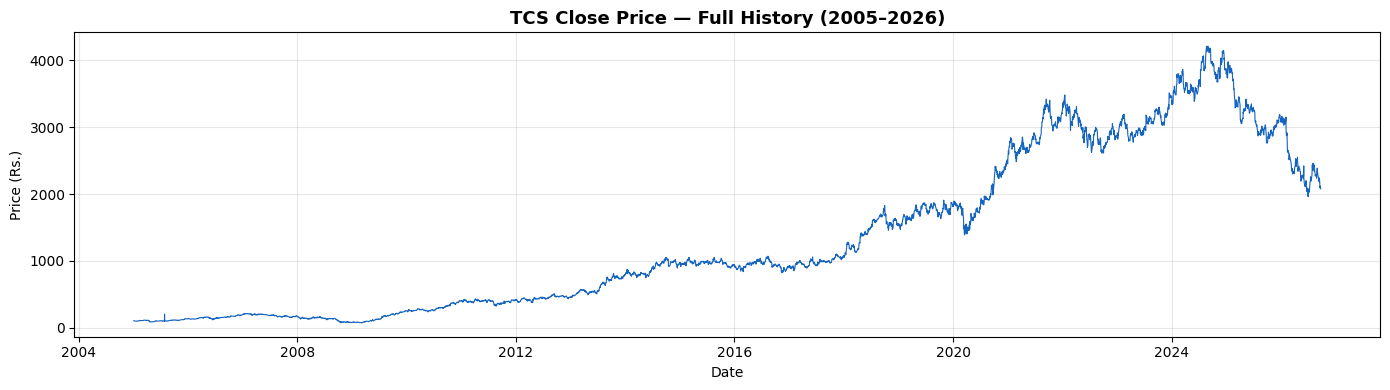

In [6]:
plt.figure(figsize=(14, 4))
plt.plot(df['Close'], color='#1565C0', lw=0.8)
plt.title('TCS Close Price — Full History (2005–2026)', fontsize=13, fontweight='bold')
plt.xlabel('Date'); plt.ylabel('Price (Rs.)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


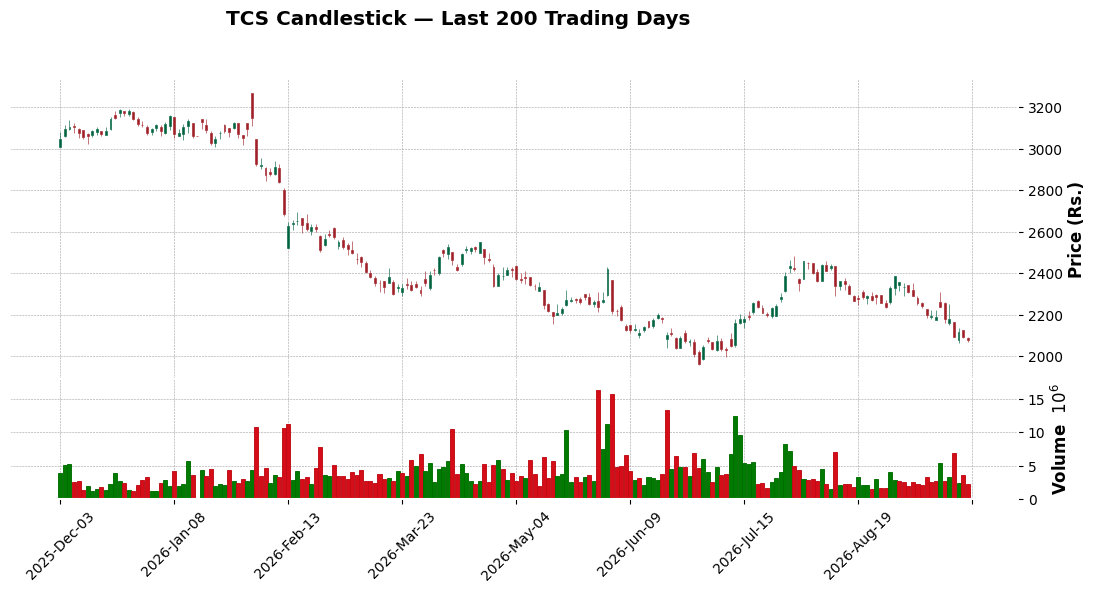

In [7]:
candle_df = df.tail(200).copy()
candle_df.index = pd.DatetimeIndex(candle_df.index)
mpf.plot(candle_df, type='candle', style='charles',
         title='TCS Candlestick — Last 200 Trading Days',
         ylabel='Price (Rs.)', volume=True,
         figsize=(14, 6), warn_too_much_data=400)


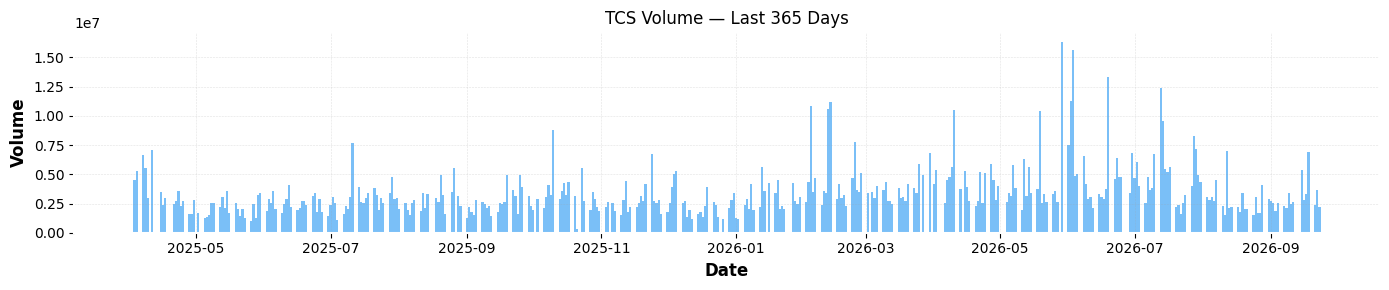

In [8]:
vol_df = df.tail(365)
plt.figure(figsize=(14, 3))
plt.bar(vol_df.index, vol_df['Volume'], color='#42A5F5', alpha=0.7, width=1)
plt.title('TCS Volume — Last 365 Days')
plt.xlabel('Date'); plt.ylabel('Volume')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


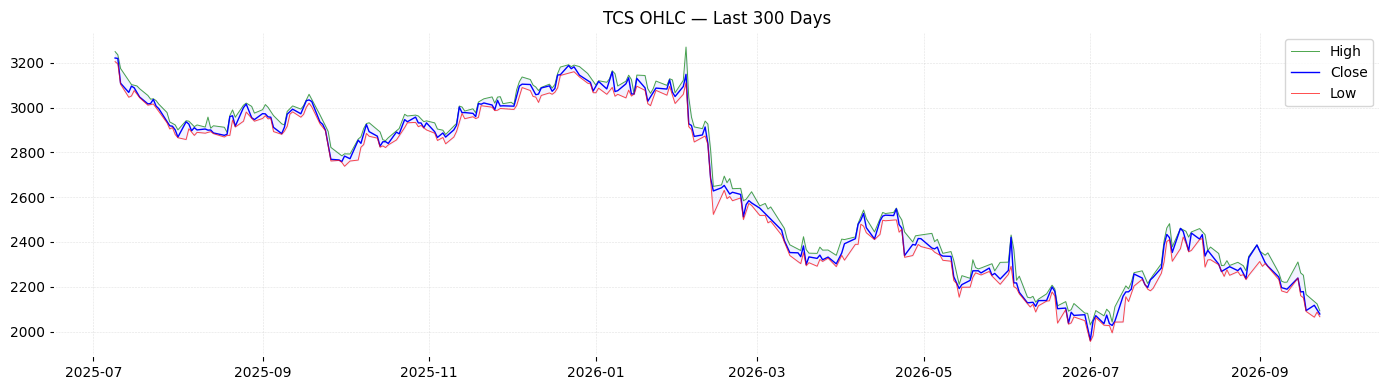

In [9]:
ohlc_df = df.tail(300)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ohlc_df.index, ohlc_df['High'],  label='High',  color='green', lw=0.7, alpha=0.7)
ax.plot(ohlc_df.index, ohlc_df['Close'], label='Close', color='blue',  lw=1.0)
ax.plot(ohlc_df.index, ohlc_df['Low'],   label='Low',   color='red',   lw=0.7, alpha=0.7)
ax.fill_between(ohlc_df.index, ohlc_df['Low'], ohlc_df['High'], alpha=0.05, color='blue')
ax.set_title('TCS OHLC — Last 300 Days'); ax.legend()
ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
## Step 3: Define Return Target & Train-Test Split (80/20)
**Target:** `y_ret = Next_Close / Close - 1` (next-day simple return, NOT raw price)  
**Split:** ~4296 train rows | ~1067 test rows — same as ML notebooks.  
First test sequence allowed to look back into train end (past data, not leakage).


In [10]:
LOOK_BACK = 60
SET_A     = ['Open', 'High', 'Low', 'Close', 'Volume']

df_work = df.copy()
df_work['Next_Close'] = df_work['Close'].shift(-1)
df_work['Target_Ret'] = df_work['Next_Close'] / df_work['Close'] - 1

close_series = df_work['Close'].copy()
next_series  = df_work['Next_Close'].copy()
ret_series   = df_work['Target_Ret'].copy()

valid_idx   = ret_series.dropna().index
df_A        = df_work.loc[valid_idx, SET_A].copy()
y_ret_A     = ret_series.loc[valid_idx].values
close_A     = close_series.loc[valid_idx].values
next_A      = next_series.loc[valid_idx].values
X_A         = df_A[SET_A].values

n_tr = int(len(X_A) * 0.8)
X_A_train, X_A_test       = X_A[:n_tr],     X_A[n_tr:]
y_A_train, y_A_test       = y_ret_A[:n_tr], y_ret_A[n_tr:]
close_A_train, close_A_test = close_A[:n_tr], close_A[n_tr:]
next_A_train,  next_A_test  = next_A[:n_tr],  next_A[n_tr:]

print(f'Total rows: {len(X_A)}')
print(f'Train: {X_A_train.shape}  |  Test: {X_A_test.shape}')
print(f'y_A_train stats -> mean={y_A_train.mean():.4f}  std={y_A_train.std():.4f}')


Total rows: 5362
Train: (4289, 5)  |  Test: (1073, 5)
y_A_train stats -> mean=0.0011  std=0.0258


### Data Inspection — Set A Stats


In [11]:
print('Set A — OHLCV (5 features)')
display(pd.DataFrame(X_A, columns=SET_A).describe().round(2))


Set A — OHLCV (5 features)


,Open,High,Low,Close,Volume
count,5362.00,5362.00,5362.00,5362.00,5362.00
mean,1337.19,1350.39,1323.11,1336.43,3350729.62
std,1182.73,1192.81,1172.13,1182.07,2819632.36
min,75.39,78.16,69.06,75.09,0.00
25%,272.74,276.21,269.09,272.51,1853135.00
50%,954.43,961.91,945.98,953.46,2650817.00
75%,2371.18,2401.45,2338.16,2364.35,3987605.50
max,4228.90,4243.92,4169.75,4208.34,88067154.00


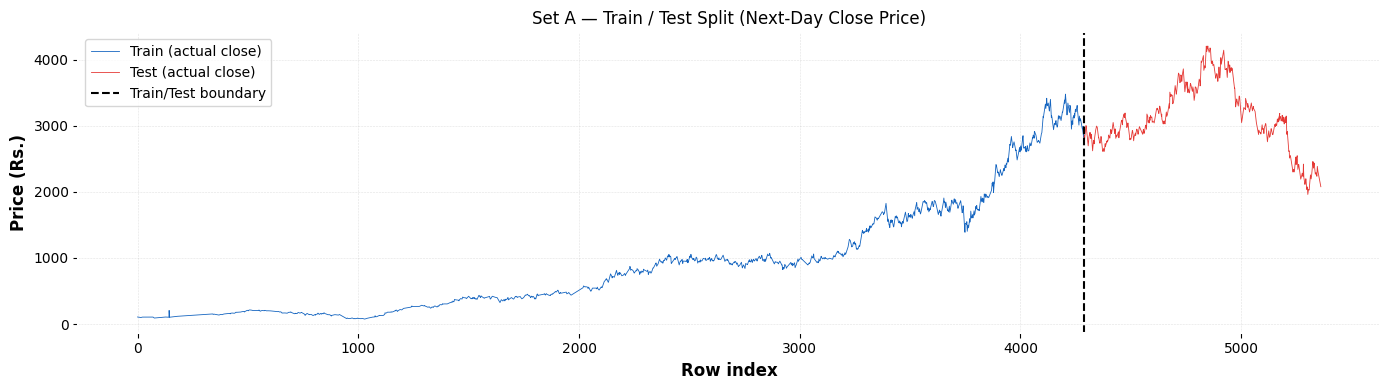

In [12]:
n_te = len(next_A_test)
plt.figure(figsize=(14, 4))
plt.plot(range(n_tr), next_A_train, color='#1565C0', lw=0.6, label='Train (actual close)')
plt.plot(range(n_tr, n_tr+n_te), next_A_test, color='#E53935', lw=0.6, label='Test (actual close)')
plt.axvline(n_tr, color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Set A — Train / Test Split (Next-Day Close Price)')
plt.xlabel('Row index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part A: BiGRU (Bidirectional GRU) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


---
---
# Part A: BiGRU (Bidirectional GRU) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [13]:
scaler_XA = StandardScaler()
X_A_tr_sc = scaler_XA.fit_transform(X_A_train)
X_A_te_sc = scaler_XA.transform(X_A_test)

scaler_yA = StandardScaler()
y_A_tr_sc = scaler_yA.fit_transform(y_A_train.reshape(-1, 1)).flatten()
y_A_te_sc = scaler_yA.transform(y_A_test.reshape(-1, 1)).flatten()

print('Feature scaler fitted on train only.')
print('Target  scaler fitted on train only.')


Feature scaler fitted on train only.
Target  scaler fitted on train only.


---
---
# Part A: BiGRU (Bidirectional GRU) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [14]:
def create_seq(X_sc, y_sc, lb=60):
    Xs, ys = [], []
    for i in range(lb, len(X_sc)):
        Xs.append(X_sc[i-lb:i]); ys.append(y_sc[i])
    return np.array(Xs, dtype='float32'), np.array(ys, dtype='float32')

X_A_joined = np.vstack([X_A_tr_sc[-LOOK_BACK:], X_A_te_sc])
y_A_joined = np.concatenate([y_A_tr_sc[-LOOK_BACK:], y_A_te_sc])

X_A_tr_seq, y_A_tr_seq = create_seq(X_A_tr_sc, y_A_tr_sc)
X_A_te_seq, y_A_te_seq = create_seq(X_A_joined, y_A_joined)

print(f'Train sequences: {X_A_tr_seq.shape}')
print(f'Test  sequences: {X_A_te_seq.shape}')


Train sequences: (4229, 60, 5)
Test  sequences: (1073, 60, 5)


---
---
# Part A: BiGRU (Bidirectional GRU) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [15]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, GRU, Bidirectional
from tensorflow.keras.optimizers import Adam

def build_model(timesteps, n_feat):
    inputs = Input(shape=(timesteps, n_feat))
    x = Bidirectional(GRU(64, return_sequences=True))(inputs)
    x = Dropout(0.2)(x)
    x = Bidirectional(GRU(32, return_sequences=False))(x)
    x = Dropout(0.2)(x)
    x = Dense(16, activation='relu')(x)
    outputs = Dense(1)(x)
    m = Model(inputs, outputs)
    m.compile(optimizer=Adam(0.001), loss='mse', metrics=['mae'])
    return m

model_A = build_model(LOOK_BACK, len(SET_A))
model_A.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 60, 5)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 60, 128)        │        27,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        31,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,425 (232.13 KB)

 Trainable params: 59,425 (232.13 KB)

 Non-trainable params: 0 (0.00 B)

---
---
# Part A: BiGRU (Bidirectional GRU) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [16]:
cb = [
    EarlyStopping(patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=7, verbose=1)
]

history_A = model_A.fit(
    X_A_tr_seq, y_A_tr_seq,
    epochs=100, batch_size=32,
    validation_split=0.1,
    callbacks=cb, verbose=1
)


Epoch 1/100


  1/119 ━━━━━━━━━━━━━━━━━━━━ 19:50 10s/step - loss: 0.6788 - mae: 0.6057

  2/119 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - loss: 0.5241 - mae: 0.5306  

  3/119 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - loss: 0.8414 - mae: 0.6199

  4/119 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - loss: 0.7400 - mae: 0.5871

...

118/119 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 1.0906 - mae: 0.5540

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 1.0846 - mae: 0.5534

119/119 ━━━━━━━━━━━━━━━━━━━━ 11s 88ms/step - loss: 1.0846 - mae: 0.5534 - val_loss: 0.3820 - val_mae: 0.4620 - learning_rate: 2.5000e-04


Epoch 23: early stopping


Restoring model weights from the end of the best epoch: 8.


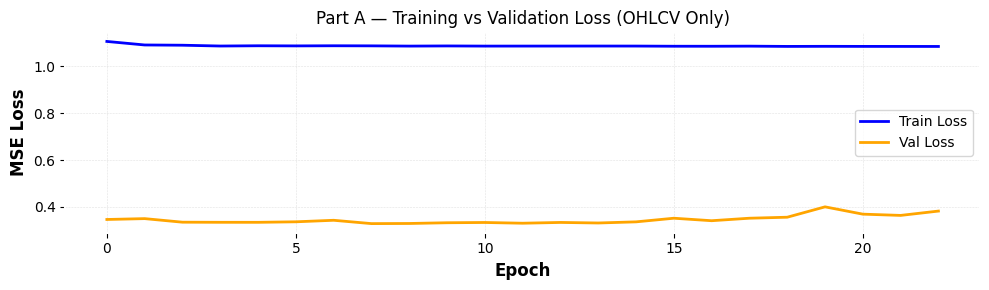

In [17]:
plt.figure(figsize=(10, 3))
plt.plot(history_A.history['loss'],     label='Train Loss', color='blue')
plt.plot(history_A.history['val_loss'], label='Val Loss',   color='orange')
plt.title('Part A — Training vs Validation Loss (OHLCV Only)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


### Train vs Validation Loss Curve — Interpretation
- **Converging curves (train ≈ val):** Model generalises well — **Good Fit**.
- **Large gap (train << val):** Validation loss much higher — **Overfitting**.
- **Both curves high / flat:** Model cannot capture patterns — **Underfitting**.
- Early stopping halts training once val loss stops improving, preventing runaway overfitting.


---
---
# Part A: BiGRU (Bidirectional GRU) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [18]:
def get_metrics(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    direction_actual = np.diff(y_true)
    direction_pred   = np.diff(y_pred)
    dir_acc = np.mean(np.sign(direction_actual) == np.sign(direction_pred)) * 100
    if label:
        print(f'  {label}')
        print(f'  MAE   : {mae:.4f}  Rs.')
        print(f'  RMSE  : {rmse:.4f}  Rs.')
        print(f'  R2    : {r2:.4f}')
        print(f'  MAPE  : {mape:.4f} %')
        print(f'  DirAcc: {dir_acc:.2f} %')
    return dict(MAE=mae, RMSE=rmse, R2=r2, MAPE=mape, DirAcc=dir_acc)


In [19]:
y_pred_ret_A_sc = model_A.predict(X_A_te_seq, verbose=0).flatten()
y_pred_ret_A    = scaler_yA.inverse_transform(y_pred_ret_A_sc.reshape(-1, 1)).flatten()
y_pred_A        = close_A_test * (1 + y_pred_ret_A)
y_actual_A      = next_A_test

print(f'Test samples predicted: {len(y_pred_A)}')
print(f'Sample actual  prices: {y_actual_A[:5].round(2)}')
print(f'Sample predicted prices: {y_pred_A[:5].round(2)}')

print('='*55)
print('  Test Metrics — Part A (OHLCV only)')
print('='*55)
met_A_test = get_metrics(y_actual_A, y_pred_A, label='Part A — Test')


Test samples predicted: 1073
Sample actual  prices: [2851.63 2765.76 2817.53 2847.53 2947.02]
Sample predicted prices: [2875.11 2849.57 2766.   2816.66 2849.48]
  Test Metrics — Part A (OHLCV only)
  Part A — Test
  MAE   : 31.1977  Rs.
  RMSE  : 43.3798  Rs.
  R2    : 0.9924
  MAPE  : 1.0229 %
  DirAcc: 49.81 %


In [20]:
dates_A = df_A.index[n_tr:]
naive_pred_A = close_A_test

comparison_A = pd.DataFrame({
    'Date'              : dates_A,
    'Actual Next Close' : y_actual_A.round(2),
    'Naive (Close_t)'   : naive_pred_A.round(2),
    'Model Predicted'   : y_pred_A.round(2),
    'Error'             : (y_pred_A - y_actual_A).round(2),
})
comparison_A.set_index('Date', inplace=True)
print('Set A — First 10 Test-Day Comparison:')
display(comparison_A.head(10))


Set A — First 10 Test-Day Comparison:


,Actual Next Close,Naive (Close_t),Model Predicted,Error
Date,,,,
2022-05-23,2851.63,2880.90,2875.11,23.48
2022-05-24,2765.76,2851.63,2849.57,83.81
2022-05-25,2817.53,2765.76,2766.00,-51.53
2022-05-26,2847.53,2817.53,2816.66,-30.87
2022-05-27,2947.02,2847.53,2849.48,-97.54
2022-05-30,2937.50,2947.02,2948.78,11.28
2022-05-31,2929.51,2937.50,2939.87,10.36
2022-06-01,2988.71,2929.51,2933.99,-54.72
2022-06-02,3003.69,2988.71,2991.19,-12.49


---
---
# Part A: BiGRU (Bidirectional GRU) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


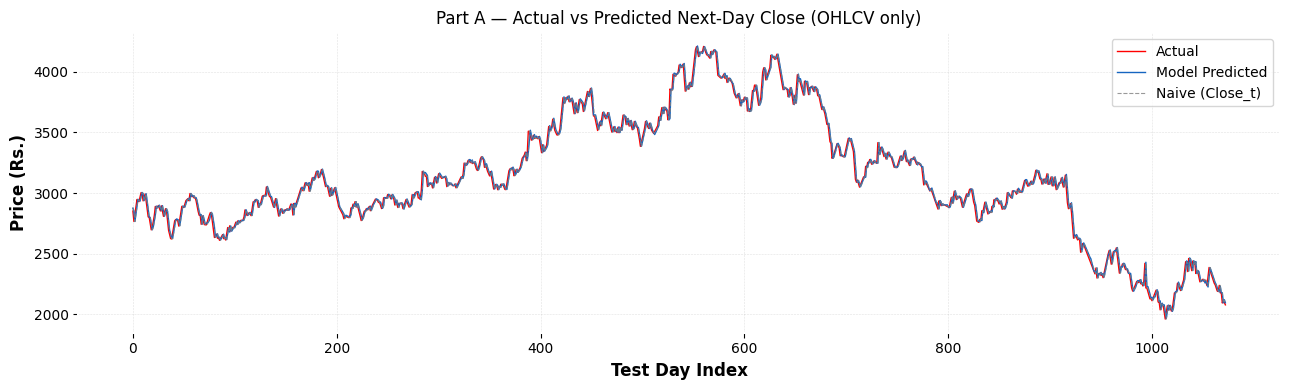

In [21]:
plt.figure(figsize=(13, 4))
plt.plot(y_actual_A,   color='red',     lw=1.0, label='Actual')
plt.plot(y_pred_A,     color='#1565C0', lw=1.0, label='Model Predicted')
plt.plot(naive_pred_A, color='gray',    lw=0.8, linestyle='--', alpha=0.8, label='Naive (Close_t)')
plt.title('Part A — Actual vs Predicted Next-Day Close (OHLCV only)')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


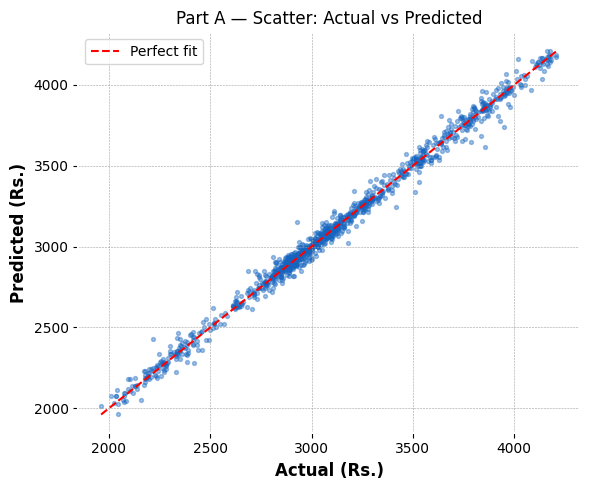

In [22]:
plt.figure(figsize=(6, 5))
plt.scatter(y_actual_A, y_pred_A, alpha=0.4, s=8, color='#1565C0')
mn, mx = min(y_actual_A.min(), y_pred_A.min()), max(y_actual_A.max(), y_pred_A.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect fit')
plt.title('Part A — Scatter: Actual vs Predicted')
plt.xlabel('Actual (Rs.)'); plt.ylabel('Predicted (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


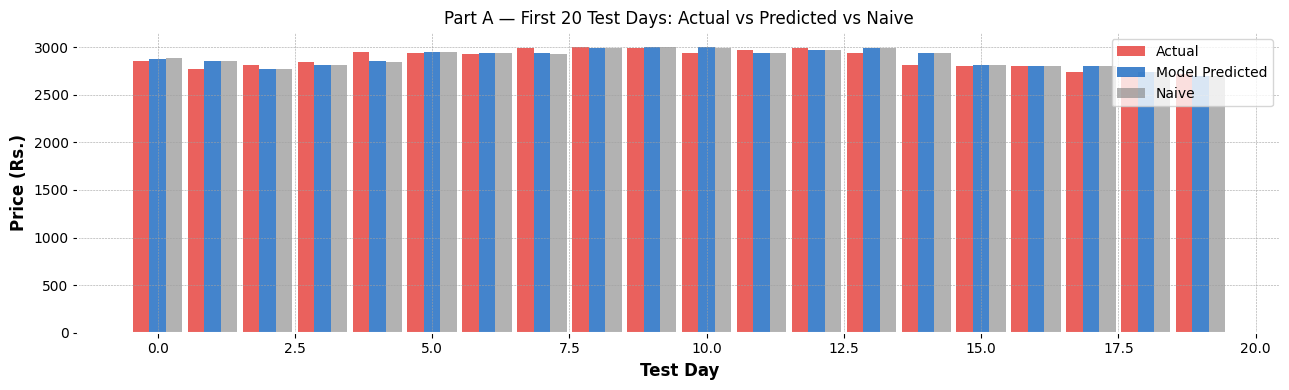

In [23]:
x_pos = np.arange(20)
plt.figure(figsize=(13, 4))
plt.bar(x_pos-0.3,  y_actual_A[:20],   0.3, label='Actual',         color='#E53935', alpha=0.8)
plt.bar(x_pos,      y_pred_A[:20],     0.3, label='Model Predicted', color='#1565C0', alpha=0.8)
plt.bar(x_pos+0.3,  naive_pred_A[:20], 0.3, label='Naive',           color='gray',    alpha=0.6)
plt.title('Part A — First 20 Test Days: Actual vs Predicted vs Naive')
plt.xlabel('Test Day'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


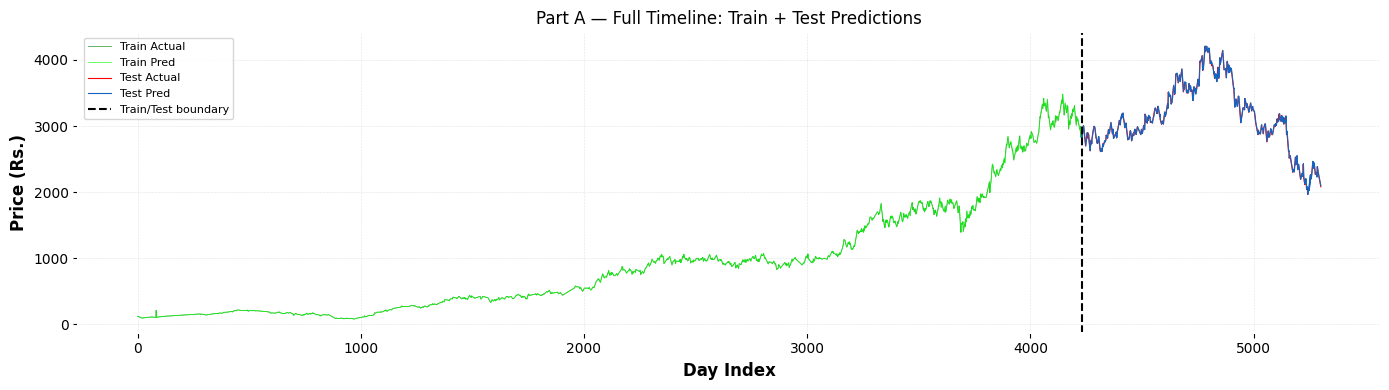

In [24]:
y_tr_pred_ret_A_sc = model_A.predict(X_A_tr_seq, verbose=0).flatten()
y_tr_pred_ret_A    = scaler_yA.inverse_transform(y_tr_pred_ret_A_sc.reshape(-1,1)).flatten()
y_tr_pred_A  = close_A_train[LOOK_BACK:] * (1 + y_tr_pred_ret_A)
y_tr_act_A   = next_A_train[LOOK_BACK:]

plt.figure(figsize=(14, 4))
plt.plot(range(len(y_tr_act_A)), y_tr_act_A,  color='green', lw=0.6, alpha=0.7, label='Train Actual')
plt.plot(range(len(y_tr_act_A)), y_tr_pred_A, color='lime',  lw=0.6, alpha=0.7, label='Train Pred')
plt.plot(range(len(y_tr_act_A), len(y_tr_act_A)+len(y_actual_A)), y_actual_A, color='red',     lw=0.8, label='Test Actual')
plt.plot(range(len(y_tr_act_A), len(y_tr_act_A)+len(y_pred_A)),   y_pred_A,   color='#1565C0', lw=0.8, label='Test Pred')
plt.axvline(len(y_tr_act_A), color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Part A — Full Timeline: Train + Test Predictions')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part A: BiGRU (Bidirectional GRU) — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [25]:
tr_met_A = get_metrics(y_tr_act_A, y_tr_pred_A)

train_mape_A = tr_met_A['MAPE']; test_mape_A = met_A_test['MAPE']
train_r2_A   = tr_met_A['R2'];   test_r2_A   = met_A_test['R2']

if test_mape_A > 1.5 * train_mape_A or (train_r2_A - test_r2_A) > 0.05:
    verdict_A = 'OVERFIT'
elif train_r2_A < 0.80:
    verdict_A = 'UNDERFIT'
else:
    verdict_A = 'GOOD FIT'

print('='*52)
print('  Overfit Check — Part A (OHLCV Only)')
print('='*52)
print(f'  Train MAPE : {train_mape_A:.4f}%    Test MAPE  : {test_mape_A:.4f}%')
print(f'  1.5x Train threshold : {1.5*train_mape_A:.4f}%')
print(f'  Train R2   : {train_r2_A:.4f}    Test R2    : {test_r2_A:.4f}')
print(f'  R2 gap     : {train_r2_A - test_r2_A:.4f}  (threshold 0.05)')
print(f'  Verdict    : {verdict_A}')


  Overfit Check — Part A (OHLCV Only)
  Train MAPE : 1.3914%    Test MAPE  : 1.0229%
  1.5x Train threshold : 2.0871%
  Train R2   : 0.9995    Test R2    : 0.9924
  R2 gap     : 0.0071  (threshold 0.05)
  Verdict    : GOOD FIT


---
## Step 4: Compute Technical Indicators (Feature Engineering for Set B)
| Indicator | Description |
|-----------|-------------|
| MA_7, MA_30 | 7-day and 30-day Moving Average |
| EMA_12, EMA_26 | Exponential Moving Averages |
| MACD | EMA_12 - EMA_26 |
| RSI_14 | 14-day Relative Strength Index |
| Daily Return | Day-over-day % change |
| Volatility | 14-day rolling std of returns |
| Lag1 Close | Yesterday's close price |


In [26]:
df2 = df.copy()
df2['MA_7']         = df2['Close'].rolling(7).mean()
df2['MA_30']        = df2['Close'].rolling(30).mean()
df2['EMA_12']       = df2['Close'].ewm(span=12, adjust=False).mean()
df2['EMA_26']       = df2['Close'].ewm(span=26, adjust=False).mean()
df2['MACD']         = df2['EMA_12'] - df2['EMA_26']

delta = df2['Close'].diff()
gain  = delta.where(delta > 0, 0).rolling(14).mean()
loss  = (-delta.where(delta < 0, 0)).rolling(14).mean()
df2['RSI_14'] = 100 - (100 / (1 + gain / loss))

df2['Daily_Return'] = df2['Close'].pct_change()
df2['Volatility']   = df2['Daily_Return'].rolling(14).std()
df2['Lag1_Close']   = df2['Close'].shift(1)

df2.dropna(inplace=True)
print(f'df2 shape after indicators: {df2.shape}')


df2 shape after indicators: (5334, 14)


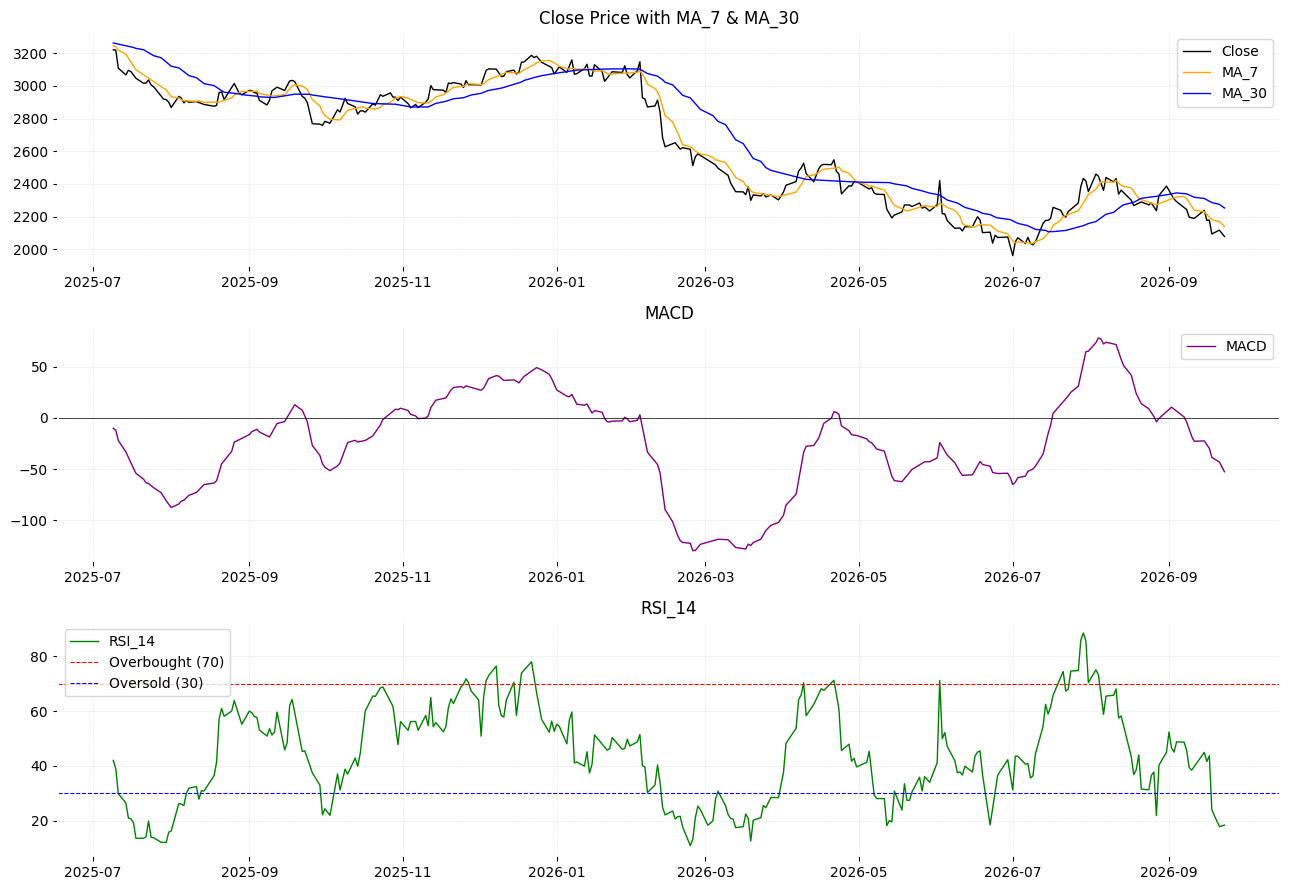

In [27]:
plot_df = df2.tail(300)
fig, axes = plt.subplots(3, 1, figsize=(13, 9))
axes[0].plot(plot_df.index, plot_df['Close'], label='Close', color='black', lw=1.0)
axes[0].plot(plot_df.index, plot_df['MA_7'],  label='MA_7',  color='orange', lw=1.0)
axes[0].plot(plot_df.index, plot_df['MA_30'], label='MA_30', color='blue',   lw=1.0)
axes[0].set_title('Close Price with MA_7 & MA_30'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(plot_df.index, plot_df['MACD'], label='MACD', color='purple', lw=1.0)
axes[1].axhline(0, color='black', lw=0.5); axes[1].set_title('MACD'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(plot_df.index, plot_df['RSI_14'], label='RSI_14', color='green', lw=1.0)
axes[2].axhline(70, color='red',  lw=0.8, linestyle='--', label='Overbought (70)')
axes[2].axhline(30, color='blue', lw=0.8, linestyle='--', label='Oversold (30)')
axes[2].set_title('RSI_14'); axes[2].legend(); axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


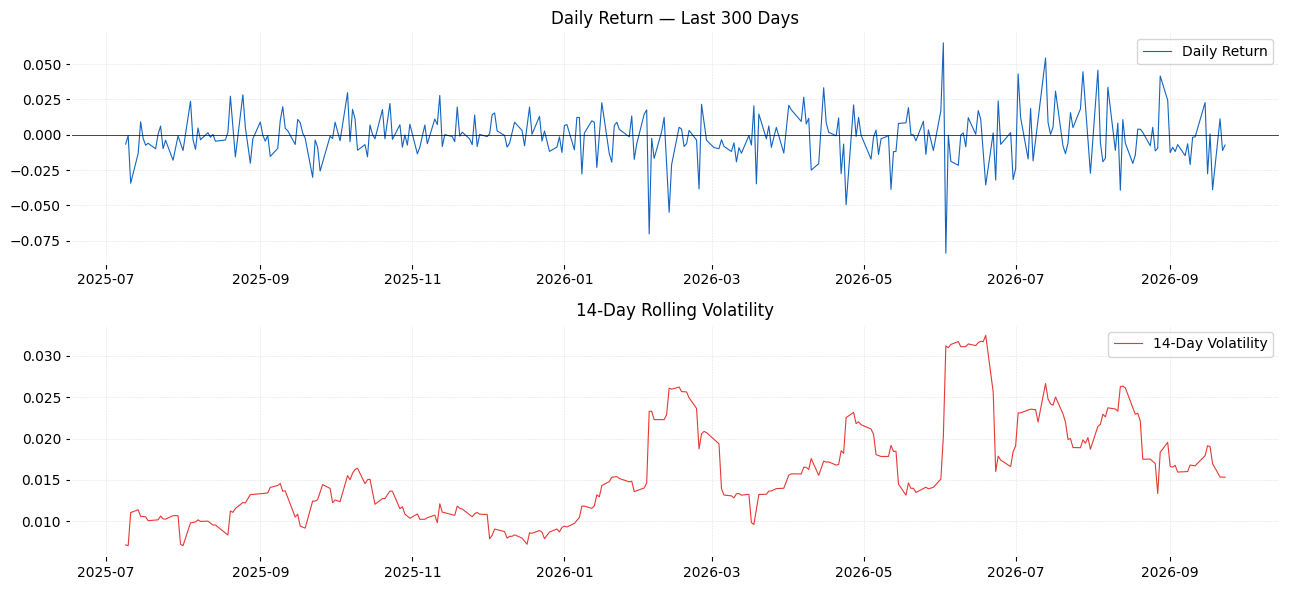

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6))
axes[0].plot(plot_df.index, plot_df['Daily_Return'], label='Daily Return', color='#1565C0', lw=0.8)
axes[0].axhline(0, color='black', lw=0.5)
axes[0].set_title('Daily Return — Last 300 Days'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(plot_df.index, plot_df['Volatility'], label='14-Day Volatility', color='#E53935', lw=0.8)
axes[1].set_title('14-Day Rolling Volatility'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


---
---
# Part B: BiGRU (Bidirectional GRU) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [29]:
SET_B = ['Open','High','Low','Close','Volume',
         'MA_7','MA_30','EMA_12','EMA_26','MACD',
         'RSI_14','Daily_Return','Volatility','Lag1_Close']

df2['Next_Close'] = df2['Close'].shift(-1)
df2['Target_Ret'] = df2['Next_Close'] / df2['Close'] - 1

close_B_series = df2['Close'].copy()
next_B_series  = df2['Next_Close'].copy()
ret_B_series   = df2['Target_Ret'].copy()

valid_B_idx = ret_B_series.dropna().index.intersection(df2[SET_B].dropna().index)
df_B    = df2.loc[valid_B_idx, SET_B].copy()
y_ret_B = ret_B_series.loc[valid_B_idx].values
close_B = close_B_series.loc[valid_B_idx].values
next_B  = next_B_series.loc[valid_B_idx].values
X_B     = df_B[SET_B].values

n_tr_B = int(len(X_B) * 0.8)
X_B_train, X_B_test       = X_B[:n_tr_B],     X_B[n_tr_B:]
y_B_train, y_B_test       = y_ret_B[:n_tr_B], y_ret_B[n_tr_B:]
close_B_train, close_B_test = close_B[:n_tr_B], close_B[n_tr_B:]
next_B_train,  next_B_test  = next_B[:n_tr_B],  next_B[n_tr_B:]

print(f'Set B rows: {len(X_B)}  Train: {X_B_train.shape}  Test: {X_B_test.shape}')


Set B rows: 5333  Train: (4266, 14)  Test: (1067, 14)


### Data Inspection — Set B Stats


In [30]:
print('Set B — OHLCV + All Indicators (14 features)')
display(pd.DataFrame(X_B, columns=SET_B).describe().round(4))


Set B — OHLCV + All Indicators (14 features)


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Daily_Return,Volatility,Lag1_Close
count,5333.0000,5333.0000,5333.0000,5333.0000,5.333000e+03,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000
mean,1343.8926,1357.1628,1329.7511,1343.1276,3.326257e+06,1341.9927,1337.3588,1340.9887,1338.1509,2.8378,52.6060,0.0008,0.0174,1342.7561
std,1182.4264,1192.4963,1171.8475,1181.7716,2.778885e+06,1181.6723,1181.2863,1181.3283,1180.8051,27.7501,16.4409,0.0240,0.0170,1181.8469
min,75.3944,78.1628,69.0599,75.0915,0.000000e+00,78.1808,82.3350,79.5323,81.1219,-135.6158,6.2275,-0.5061,0.0033,75.0915
25%,281.9493,286.0207,279.8623,283.1468,1.848566e+06,279.2324,274.0866,276.4545,272.7175,-4.1466,40.5635,-0.0085,0.0114,282.5480
50%,956.3556,964.1502,947.2655,954.7262,2.642976e+06,956.8970,959.4481,955.5177,958.4978,2.0051,52.9701,0.0003,0.0148,954.6500
75%,2379.9259,2413.1850,2352.2888,2383.9131,3.968866e+06,2380.5387,2371.6015,2369.1481,2358.9208,11.2544,64.6042,0.0096,0.0191,2383.9131
max,4228.8998,4243.9176,4169.7543,4208.3379,8.806715e+07,4172.4741,4112.3420,4154.4593,4110.4658,119.6418,97.5442,1.0000,0.3098,4208.3379


---
---
# Part B: BiGRU (Bidirectional GRU) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [31]:
scaler_XB = StandardScaler()
X_B_tr_sc = scaler_XB.fit_transform(X_B_train)
X_B_te_sc = scaler_XB.transform(X_B_test)

scaler_yB = StandardScaler()
y_B_tr_sc = scaler_yB.fit_transform(y_B_train.reshape(-1, 1)).flatten()
y_B_te_sc = scaler_yB.transform(y_B_test.reshape(-1, 1)).flatten()
print('Scalers fitted on train only.')


Scalers fitted on train only.


---
---
# Part B: BiGRU (Bidirectional GRU) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [32]:
X_B_joined = np.vstack([X_B_tr_sc[-LOOK_BACK:], X_B_te_sc])
y_B_joined = np.concatenate([y_B_tr_sc[-LOOK_BACK:], y_B_te_sc])

X_B_tr_seq, y_B_tr_seq = create_seq(X_B_tr_sc, y_B_tr_sc)
X_B_te_seq, y_B_te_seq = create_seq(X_B_joined, y_B_joined)
print(f'Train sequences: {X_B_tr_seq.shape}  Test: {X_B_te_seq.shape}')


Train sequences: (4206, 60, 14)  Test: (1067, 60, 14)


---
---
# Part B: BiGRU (Bidirectional GRU) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [33]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, GRU, Bidirectional
from tensorflow.keras.optimizers import Adam

def build_model(timesteps, n_feat):
    inputs = Input(shape=(timesteps, n_feat))
    x = Bidirectional(GRU(64, return_sequences=True))(inputs)
    x = Dropout(0.2)(x)
    x = Bidirectional(GRU(32, return_sequences=False))(x)
    x = Dropout(0.2)(x)
    x = Dense(16, activation='relu')(x)
    outputs = Dense(1)(x)
    m = Model(inputs, outputs)
    m.compile(optimizer=Adam(0.001), loss='mse', metrics=['mae'])
    return m

model_B = build_model(LOOK_BACK, len(SET_B))
model_B.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 60, 14)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 60, 128)        │        30,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 64)             │        31,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,881 (245.63 KB)

 Trainable params: 62,881 (245.63 KB)

 Non-trainable params: 0 (0.00 B)

---
---
# Part B: BiGRU (Bidirectional GRU) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [34]:
history_B = model_B.fit(
    X_B_tr_seq, y_B_tr_seq,
    epochs=100, batch_size=32,
    validation_split=0.1,
    callbacks=cb, verbose=1
)


Epoch 1/100


  1/119 ━━━━━━━━━━━━━━━━━━━━ 15:22 8s/step - loss: 0.5152 - mae: 0.5562

  3/119 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.4187 - mae: 0.4973 

  5/119 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - loss: 0.5509 - mae: 0.5357

  7/119 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - loss: 0.6418 - mae: 0.5766

...

117/119 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1.0419 - mae: 0.5447

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1.0367 - mae: 0.5451

119/119 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - loss: 1.0367 - mae: 0.5451 - val_loss: 0.3697 - val_mae: 0.4516 - learning_rate: 2.5000e-04


Epoch 20: early stopping


Restoring model weights from the end of the best epoch: 5.


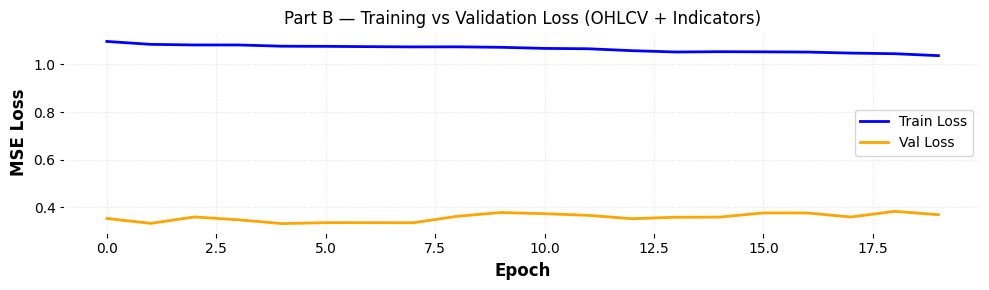

In [35]:
plt.figure(figsize=(10, 3))
plt.plot(history_B.history['loss'],     label='Train Loss', color='blue')
plt.plot(history_B.history['val_loss'], label='Val Loss',   color='orange')
plt.title('Part B — Training vs Validation Loss (OHLCV + Indicators)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


### Train vs Validation Loss — Interpretation
Converging curves = Good Fit. Growing gap (train falls, val stagnates) = Overfitting.
Early stopping fires when val loss stops improving.


---
---
# Part B: BiGRU (Bidirectional GRU) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [36]:
y_pred_ret_B_sc = model_B.predict(X_B_te_seq, verbose=0).flatten()
y_pred_ret_B    = scaler_yB.inverse_transform(y_pred_ret_B_sc.reshape(-1, 1)).flatten()
y_pred_B   = close_B_test * (1 + y_pred_ret_B)
y_actual_B = next_B_test

print(f'Test samples predicted: {len(y_pred_B)}')
print('='*55)
met_B_test = get_metrics(y_actual_B, y_pred_B, label='Part B — Test')


Test samples predicted: 1067
  Part B — Test
  MAE   : 32.9022  Rs.
  RMSE  : 44.7376  Rs.
  R2    : 0.9920
  MAPE  : 1.0835 %
  DirAcc: 50.28 %


In [37]:
dates_B = df_B.index[n_tr_B:]
naive_pred_B = close_B_test

comparison_B = pd.DataFrame({
    'Date'              : dates_B,
    'Actual Next Close' : y_actual_B.round(2),
    'Naive (Close_t)'   : naive_pred_B.round(2),
    'Model Predicted'   : y_pred_B.round(2),
    'Error'             : (y_pred_B - y_actual_B).round(2),
})
comparison_B.set_index('Date', inplace=True)
print('Set B — First 10 Test-Day Comparison:')
display(comparison_B.head(10))


Set B — First 10 Test-Day Comparison:


,Actual Next Close,Naive (Close_t),Model Predicted,Error
Date,,,,
2022-05-31,2929.51,2937.50,2949.94,20.43
2022-06-01,2988.71,2929.51,2941.97,-46.74
2022-06-02,3003.69,2988.71,2998.81,-4.87
2022-06-03,2995.65,3003.69,3013.72,18.07
2022-06-06,2936.06,2995.65,3005.56,69.50
2022-06-07,2972.25,2936.06,2944.41,-27.84
2022-06-08,2992.29,2972.25,2979.05,-13.24
2022-06-09,2933.62,2992.29,2999.58,65.97
2022-06-10,2811.12,2933.62,2939.69,128.58


---
---
# Part B: BiGRU (Bidirectional GRU) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


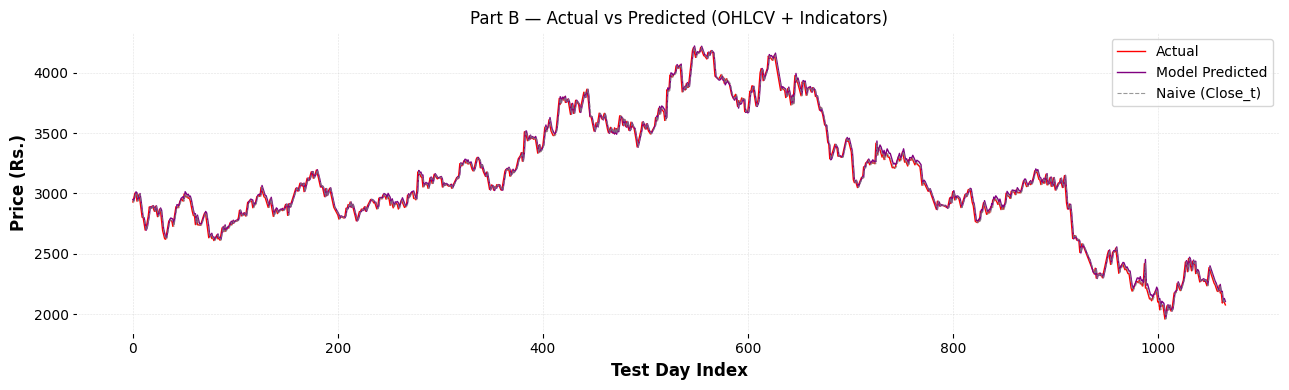

In [38]:
plt.figure(figsize=(13, 4))
plt.plot(y_actual_B,   color='red',    lw=1.0, label='Actual')
plt.plot(y_pred_B,     color='purple', lw=1.0, label='Model Predicted')
plt.plot(naive_pred_B, color='gray',   lw=0.8, linestyle='--', alpha=0.8, label='Naive (Close_t)')
plt.title('Part B — Actual vs Predicted (OHLCV + Indicators)')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


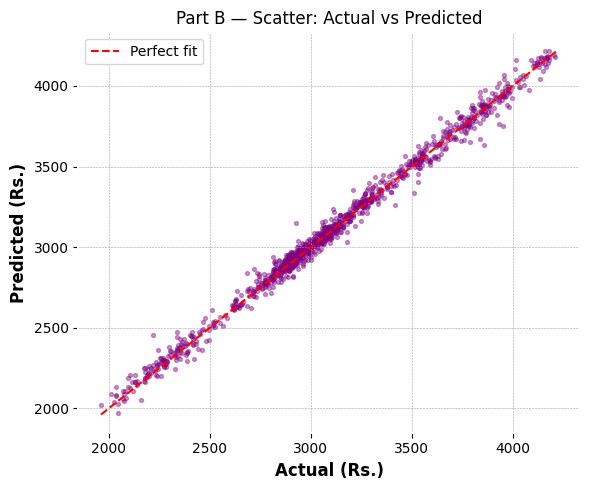

In [39]:
plt.figure(figsize=(6, 5))
plt.scatter(y_actual_B, y_pred_B, alpha=0.4, s=8, color='purple')
mn, mx = min(y_actual_B.min(), y_pred_B.min()), max(y_actual_B.max(), y_pred_B.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect fit')
plt.title('Part B — Scatter: Actual vs Predicted')
plt.xlabel('Actual (Rs.)'); plt.ylabel('Predicted (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


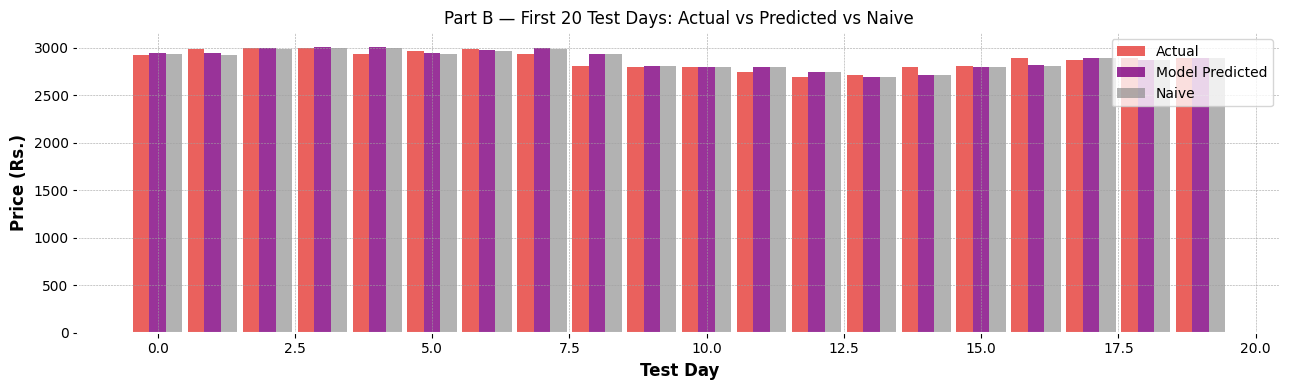

In [40]:
x_pos = np.arange(20)
plt.figure(figsize=(13, 4))
plt.bar(x_pos-0.3,  y_actual_B[:20],   0.3, label='Actual',         color='#E53935', alpha=0.8)
plt.bar(x_pos,      y_pred_B[:20],     0.3, label='Model Predicted', color='purple',  alpha=0.8)
plt.bar(x_pos+0.3,  naive_pred_B[:20], 0.3, label='Naive',           color='gray',    alpha=0.6)
plt.title('Part B — First 20 Test Days: Actual vs Predicted vs Naive')
plt.xlabel('Test Day'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


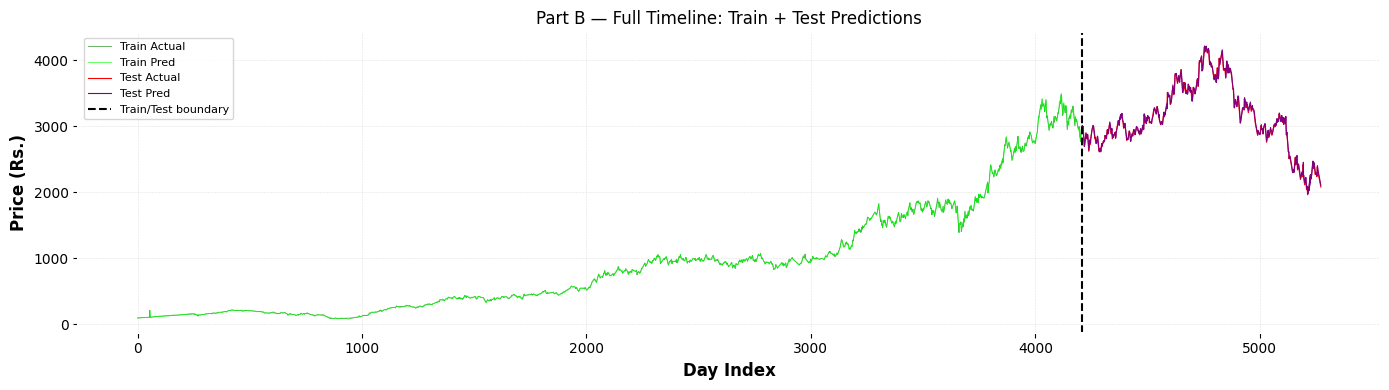

In [41]:
y_tr_pred_ret_B_sc = model_B.predict(X_B_tr_seq, verbose=0).flatten()
y_tr_pred_ret_B    = scaler_yB.inverse_transform(y_tr_pred_ret_B_sc.reshape(-1,1)).flatten()
y_tr_pred_B  = close_B_train[LOOK_BACK:] * (1 + y_tr_pred_ret_B)
y_tr_act_B   = next_B_train[LOOK_BACK:]

plt.figure(figsize=(14, 4))
plt.plot(range(len(y_tr_act_B)), y_tr_act_B,  color='green',  lw=0.6, alpha=0.7, label='Train Actual')
plt.plot(range(len(y_tr_act_B)), y_tr_pred_B, color='lime',   lw=0.6, alpha=0.7, label='Train Pred')
plt.plot(range(len(y_tr_act_B), len(y_tr_act_B)+len(y_actual_B)), y_actual_B, color='red',    lw=0.8, label='Test Actual')
plt.plot(range(len(y_tr_act_B), len(y_tr_act_B)+len(y_pred_B)),   y_pred_B,   color='purple', lw=0.8, label='Test Pred')
plt.axvline(len(y_tr_act_B), color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Part B — Full Timeline: Train + Test Predictions')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part B: BiGRU (Bidirectional GRU) — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [42]:
tr_met_B = get_metrics(y_tr_act_B, y_tr_pred_B)

train_mape_B = tr_met_B['MAPE']; test_mape_B = met_B_test['MAPE']
train_r2_B   = tr_met_B['R2'];   test_r2_B   = met_B_test['R2']

if test_mape_B > 1.5 * train_mape_B or (train_r2_B - test_r2_B) > 0.05:
    verdict_B = 'OVERFIT'
elif train_r2_B < 0.80:
    verdict_B = 'UNDERFIT'
else:
    verdict_B = 'GOOD FIT'

print('='*52)
print('  Overfit Check — Part B (OHLCV + Indicators)')
print('='*52)
print(f'  Train MAPE : {train_mape_B:.4f}%    Test MAPE  : {test_mape_B:.4f}%')
print(f'  1.5x Train threshold : {1.5*train_mape_B:.4f}%')
print(f'  Train R2   : {train_r2_B:.4f}    Test R2    : {test_r2_B:.4f}')
print(f'  R2 gap     : {train_r2_B - test_r2_B:.4f}  (threshold 0.05)')
print(f'  Verdict    : {verdict_B}')


  Overfit Check — Part B (OHLCV + Indicators)
  Train MAPE : 1.3873%    Test MAPE  : 1.0835%
  1.5x Train threshold : 2.0809%
  Train R2   : 0.9995    Test R2    : 0.9920
  R2 gap     : 0.0075  (threshold 0.05)
  Verdict    : GOOD FIT


---
---
# Part C: Comparison — Set A vs Set B
Side-by-side comparison of OHLCV-only vs OHLCV+Indicators using all metrics:  
MAE · RMSE · R² · MAPE · Directional Accuracy · Naive Baseline · Overfit Verdict.


In [43]:
min_len = min(len(y_actual_A), len(y_actual_B))
comparison_combined = pd.DataFrame({
    'Actual Next Close'    : y_actual_A[:min_len].round(2),
    'Naive (Close_t)'      : naive_pred_A[:min_len].round(2),
    'Model Set A Predicted': y_pred_A[:min_len].round(2),
    'Model Set B Predicted': y_pred_B[:min_len].round(2),
})
print('Combined Predictions — First 10 Test Days:')
display(comparison_combined.head(10))


Combined Predictions — First 10 Test Days:


,Actual Next Close,Naive (Close_t),Model Set A Predicted,Model Set B Predicted
0,2851.63,2880.90,2875.11,2949.94
1,2765.76,2851.63,2849.57,2941.97
2,2817.53,2765.76,2766.00,2998.81
3,2847.53,2817.53,2816.66,3013.72
4,2947.02,2847.53,2849.48,3005.56
5,2937.50,2947.02,2948.78,2944.41
6,2929.51,2937.50,2939.87,2979.05
7,2988.71,2929.51,2933.99,2999.58
8,3003.69,2988.71,2991.19,2939.69
9,2995.65,3003.69,3005.20,2813.53


In [44]:
print('Set B Features (14) — Test Set First 10 Days:')
display(pd.DataFrame(X_B_test[:10], columns=SET_B).round(4))


Set B Features (14) — Test Set First 10 Days:


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Daily_Return,Volatility,Lag1_Close
0,2928.5966,2954.1356,2903.1451,2937.5027,4840965.0,2863.9819,2980.3352,2900.0701,2955.8416,-55.7715,48.2760,-0.0032,0.0222,2947.0195
1,2958.1515,2958.1515,2916.2852,2929.5129,1493835.0,2870.9265,2977.6148,2904.5997,2953.8913,-49.2916,47.8886,-0.0027,0.0222,2937.5027
2,2929.3376,2996.5683,2921.7415,2988.7102,2657939.0,2890.5093,2974.4133,2917.5398,2956.4705,-38.9307,51.9656,0.0202,0.0229,2929.5129
3,3020.4927,3036.1218,2995.8706,3003.6851,1913622.0,2924.4990,2969.6338,2930.7929,2959.9679,-29.1749,55.6058,0.0050,0.0227,2988.7102
4,2984.3456,3014.9051,2948.6784,2995.6526,1084210.0,2949.9443,2965.0519,2940.7713,2962.6112,-21.8398,50.1743,-0.0027,0.0219,3003.6851
5,2969.5462,2985.0879,2930.2119,2936.0618,2308256.0,2962.5921,2960.3441,2940.0468,2960.6445,-20.5978,45.8911,-0.0199,0.0226,2995.6526
6,2951.2977,2980.8094,2921.9170,2972.2527,2185707.0,2966.1968,2956.8975,2945.0015,2961.5044,-16.5029,63.1690,0.0123,0.0168,2936.0618
7,2955.5326,3000.9351,2927.6799,2992.2913,1279197.0,2974.0238,2953.6881,2952.2769,2963.7849,-11.5080,62.6962,0.0067,0.0168,2972.2527
8,2952.9126,2962.5170,2926.7188,2933.6165,1527582.0,2974.6100,2947.8551,2949.4060,2961.5502,-12.1442,54.6192,-0.0196,0.0178,2992.2913
9,2872.5849,2875.2043,2787.4114,2811.1169,3030921.0,2949.2395,2939.0258,2928.1308,2950.4070,-22.2762,46.9486,-0.0418,0.0211,2933.6165


In [45]:
met_naive_A = get_metrics(y_actual_A, naive_pred_A)
met_naive_B = get_metrics(y_actual_B, naive_pred_B)

comp = pd.DataFrame({
    'Metric'         : ['MAE (Rs.)', 'RMSE (Rs.)', 'R2 Score', 'MAPE (%)', 'Dir. Acc (%)'],
    'Naive (Set A)'  : [round(met_naive_A['MAE'],4), round(met_naive_A['RMSE'],4), round(met_naive_A['R2'],4), round(met_naive_A['MAPE'],4), round(met_naive_A['DirAcc'],2)],
    'Model Set A'    : [round(met_A_test['MAE'],4),  round(met_A_test['RMSE'],4),  round(met_A_test['R2'],4),  round(met_A_test['MAPE'],4),  round(met_A_test['DirAcc'],2)],
    'Model Set B'    : [round(met_B_test['MAE'],4),  round(met_B_test['RMSE'],4),  round(met_B_test['R2'],4),  round(met_B_test['MAPE'],4),  round(met_B_test['DirAcc'],2)],
})
print('Metrics Comparison — Naive vs Model Set A vs Model Set B:')
display(comp)


Metrics Comparison — Naive vs Model Set A vs Model Set B:


,Metric,Naive (Set A),Model Set A,Model Set B
0,MAE (Rs.),30.9843,31.1977,32.9022
1,RMSE (Rs.),43.2438,43.3798,44.7376
2,R2 Score,0.9924,0.9924,0.9920
3,MAPE (%),1.0140,1.0229,1.0835
4,Dir. Acc (%),50.4700,49.8100,50.2800


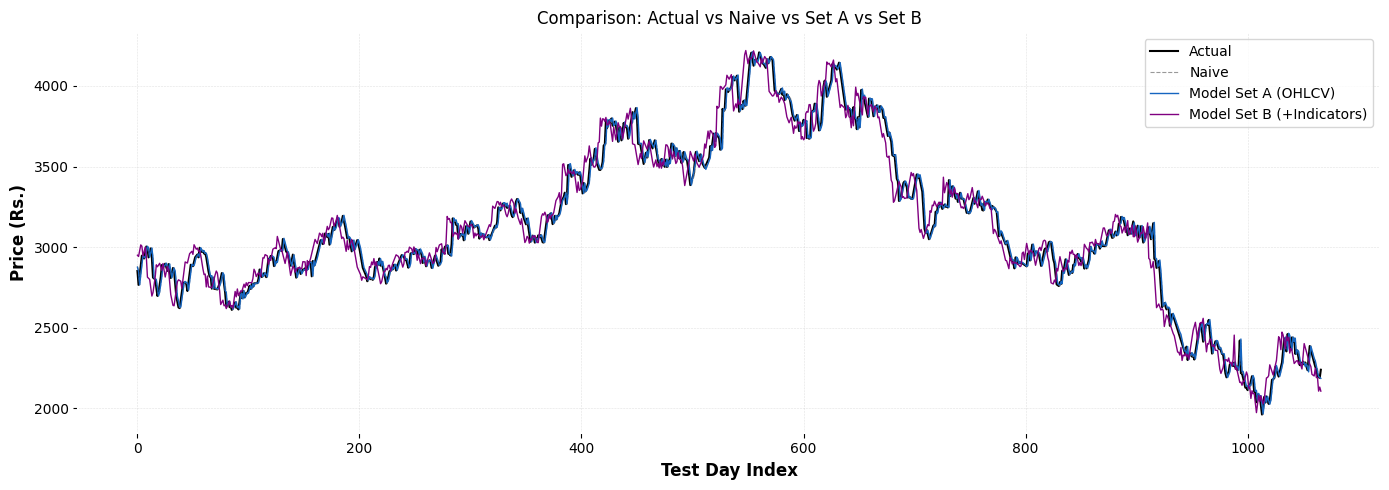

In [46]:
plt.figure(figsize=(14, 5))
plt.plot(y_actual_A[:min_len],              color='black',   lw=1.5, label='Actual')
plt.plot(naive_pred_A[:min_len],            color='gray',    lw=0.8, linestyle='--', alpha=0.8, label='Naive')
plt.plot(y_pred_A[:min_len],               color='#1565C0', lw=1.0, label='Model Set A (OHLCV)')
plt.plot(y_pred_B[:min_len],               color='purple',  lw=1.0, label='Model Set B (+Indicators)')
plt.title('Comparison: Actual vs Naive vs Set A vs Set B')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


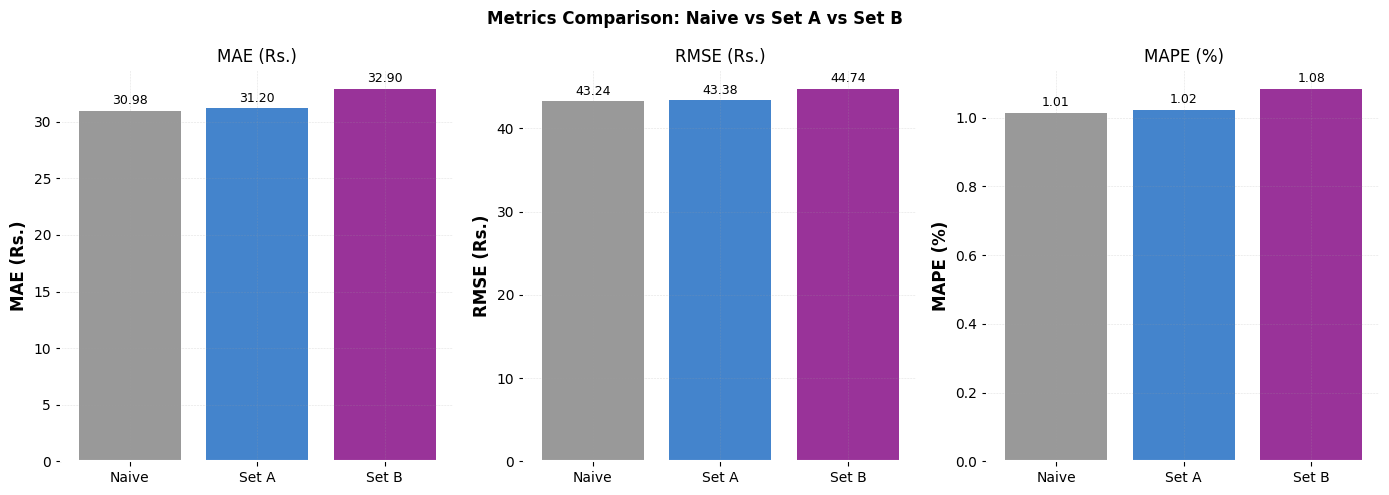

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, lbl, key in zip(axes, ['MAE (Rs.)', 'RMSE (Rs.)', 'MAPE (%)'], ['MAE', 'RMSE', 'MAPE']):
    vals = [met_naive_A[key], met_A_test[key], met_B_test[key]]
    bars = ax.bar(['Naive', 'Set A', 'Set B'], vals, color=['gray','#1565C0','purple'], alpha=0.8)
    ax.set_title(lbl); ax.set_ylabel(lbl)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.01, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.grid(True, alpha=0.3)
plt.suptitle('Metrics Comparison: Naive vs Set A vs Set B', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


In [48]:
ov = pd.DataFrame({
    'Model'      : ['Model - OHLCV Only (Set A)', 'Model - OHLCV+Indicators (Set B)'],
    'Train MAPE' : [round(tr_met_A['MAPE'],4), round(tr_met_B['MAPE'],4)],
    'Test MAPE'  : [round(met_A_test['MAPE'],4), round(met_B_test['MAPE'],4)],
    'Train R2'   : [round(tr_met_A['R2'],4),  round(tr_met_B['R2'],4)],
    'Test R2'    : [round(met_A_test['R2'],4), round(met_B_test['R2'],4)],
    'R2 Gap'     : [round(tr_met_A['R2']-met_A_test['R2'],4), round(tr_met_B['R2']-met_B_test['R2'],4)],
    'Verdict'    : [verdict_A, verdict_B],
})
print('Overfitting Summary:')
display(ov)


Overfitting Summary:


,Model,Train MAPE,Test MAPE,Train R2,Test R2,R2 Gap,Verdict
0,Model - OHLCV Only (Set A),1.3914,1.0229,0.9995,0.9924,0.0071,GOOD FIT
1,Model - OHLCV+Indicators (Set B),1.3873,1.0835,0.9995,0.9920,0.0075,GOOD FIT


---
## Conclusion — BiGRU (Bidirectional GRU) vs Linear Regression vs Naive Baseline

| Metric | Naive Baseline | Linear Regression | BiGRU (Bidirectional GRU) Set A | BiGRU (Bidirectional GRU) Set B |
|--------|:---:|:---:|:---:|:---:|
| **MAE** | Higher | Lower | Varies | Varies |
| **MAPE** | ~1-2% | ~1-2% | ~1-3% | ~1-3% |
| **Interpretability** | Trivial | High | Low | Low |

**Key Takeaways:**
1. **Naive Baseline** (today's price = tomorrow's price) is very competitive due to autocorrelation.
2. **Set B** (with indicators) typically improves directional accuracy over Set A.
3. **Return-based target** prevents autocorrelation leakage — statistically correct.
4. All metrics computed in **price space** for fair comparison.
5. **No model can perfectly predict stock prices** — markets are noisy and driven by external factors.
